<center><h1>Keehan_Alyssa_HW6</h1></center>

Name: Alyssa Keehan
<br>
Github Username: akeehan56
<br>
GitHub Links: [Class Repo](https://github.com/akeehan56/DSCI552) | [HW5](https://github.com/akeehan56/DSCI552/tree/main/HW6)
<br>
Email: akeehan@usc.edu
<br>
USC ID: 3429542433

## 1. Tree-Based Methods

Import packages

In [4]:
# ! pip install imblearn
# ! pip install imbalanced-learn

# import sys
# !{sys.executable} -m pip install imbalanced-learn

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    RocCurveDisplay,
    roc_auc_score,
    accuracy_score,
    classification_report,
    balanced_accuracy_score,
    average_precision_score,
    precision_score,
    recall_score,
)
from sklearn.base import clone

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier

### (a) Download the APS Failure data

In [12]:
data_dir = Path("../data")

train_df = pd.read_csv(
    data_dir / "aps_failure_training_set.csv",
    skiprows=20,
    na_values=["na"]
)

test_df = pd.read_csv(
    data_dir / "aps_failure_test_set.csv",
    skiprows=20,
    na_values=["na"]
)

X_train = train_df.drop(columns="class")
y_train = train_df["class"].map({"neg": 0, "pos": 1})

X_test = test_df.drop(columns="class")
y_test = test_df["class"].map({"neg": 0, "pos": 1})

print("Train:", X_train.shape, "Test:", X_test.shape)
print(train_df["class"].value_counts())

Train: (60000, 170) Test: (16000, 170)
class
neg    59000
pos     1000
Name: count, dtype: int64


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

In [13]:
imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

**Answer:**

1. **Median Imputation** fills each missing value with the median of that feature, calculated from the training data. The APS dataset contains numeric sensor features, so this is a simple and practical choice. Sensor readings can be skewed or contain extreme values; the median is less affected by those values than the mean. 
2. **KNN Imputation** fills a missing value using values from the most similar rows, called its nearest neighbors. For a numeric feature, it typically uses an average of that feature’s observed values among those neighbors; some versions give more weight to closer neighbors.

I chose median imputation as my main method because the APS dataset contains numeric sensor features, and the median is less affected by skewed values and outliers than the mean. It is also efficient for a dataset with many features.

Sources:
1. ITU Online Editorial Team. (2026, October 21). Practical techniques for handling missing data in large datasets. ITU Online IT Training. https://www.ituonline.com/blogs/practical-techniques-for-handling-missing-data-in-large-datasets/

#### (ii) Calculate the coefficient of variation

In [71]:
n_top = int(np.floor(np.sqrt(X_train_imputed.shape[1])))
cv = X_train_imputed.std(ddof=1) / X_train_imputed.mean()
cv_table = cv.rename("CV").to_frame().sort_values("CV", ascending=False)

print(cv_table.head(n_top))

                CV
cf_000  244.887517
co_000  244.507385
ad_000  244.322816
cs_009  237.930554
dh_000  123.216097
dj_000  117.494225
ag_000   92.917755
as_000   87.332500
ay_009   84.733735
ak_000   80.424975
az_009   77.838544
ch_000   77.453857
au_000   68.882751


In [72]:
top_features = cv_table.head(n_top).index.tolist()
(
    X_train_imputed[top_features]
    .agg(["mean", "std", "min", "median", "max"])
    .T
    .round(2)
    .style.format("{:.2f}")
)

,mean,std,min,median,max
cf_000,143107.53,35045248.64,0.00,2.00,8584297736.00
co_000,143330.02,35045247.84,0.00,8.00,8584297742.00
ad_000,143438.29,35045247.41,0.00,126.00,8584297742.00
cs_009,770.51,183327.80,0.00,0.00,44902992.00
dh_000,4392.64,541244.06,0.00,0.00,124700880.00
dj_000,37.27,4379.17,0.00,0.00,726750.00
ag_000,219.16,20363.64,0.00,0.00,3376892.00
as_000,125.41,10952.19,0.00,0.00,1655240.00
ay_009,1149.62,97411.56,0.00,0.00,18824656.00
ak_000,907.66,72998.59,0.00,0.00,10444924.00


**Answer:**

The highest-CV features have large variability relative to their means. Several CV values are extremely high, which may be due to means close to zero. These rankings help identify features to visualize, but CV alone does not show whether a feature predicts the class.

#### (iii) Plot a correlation matrix

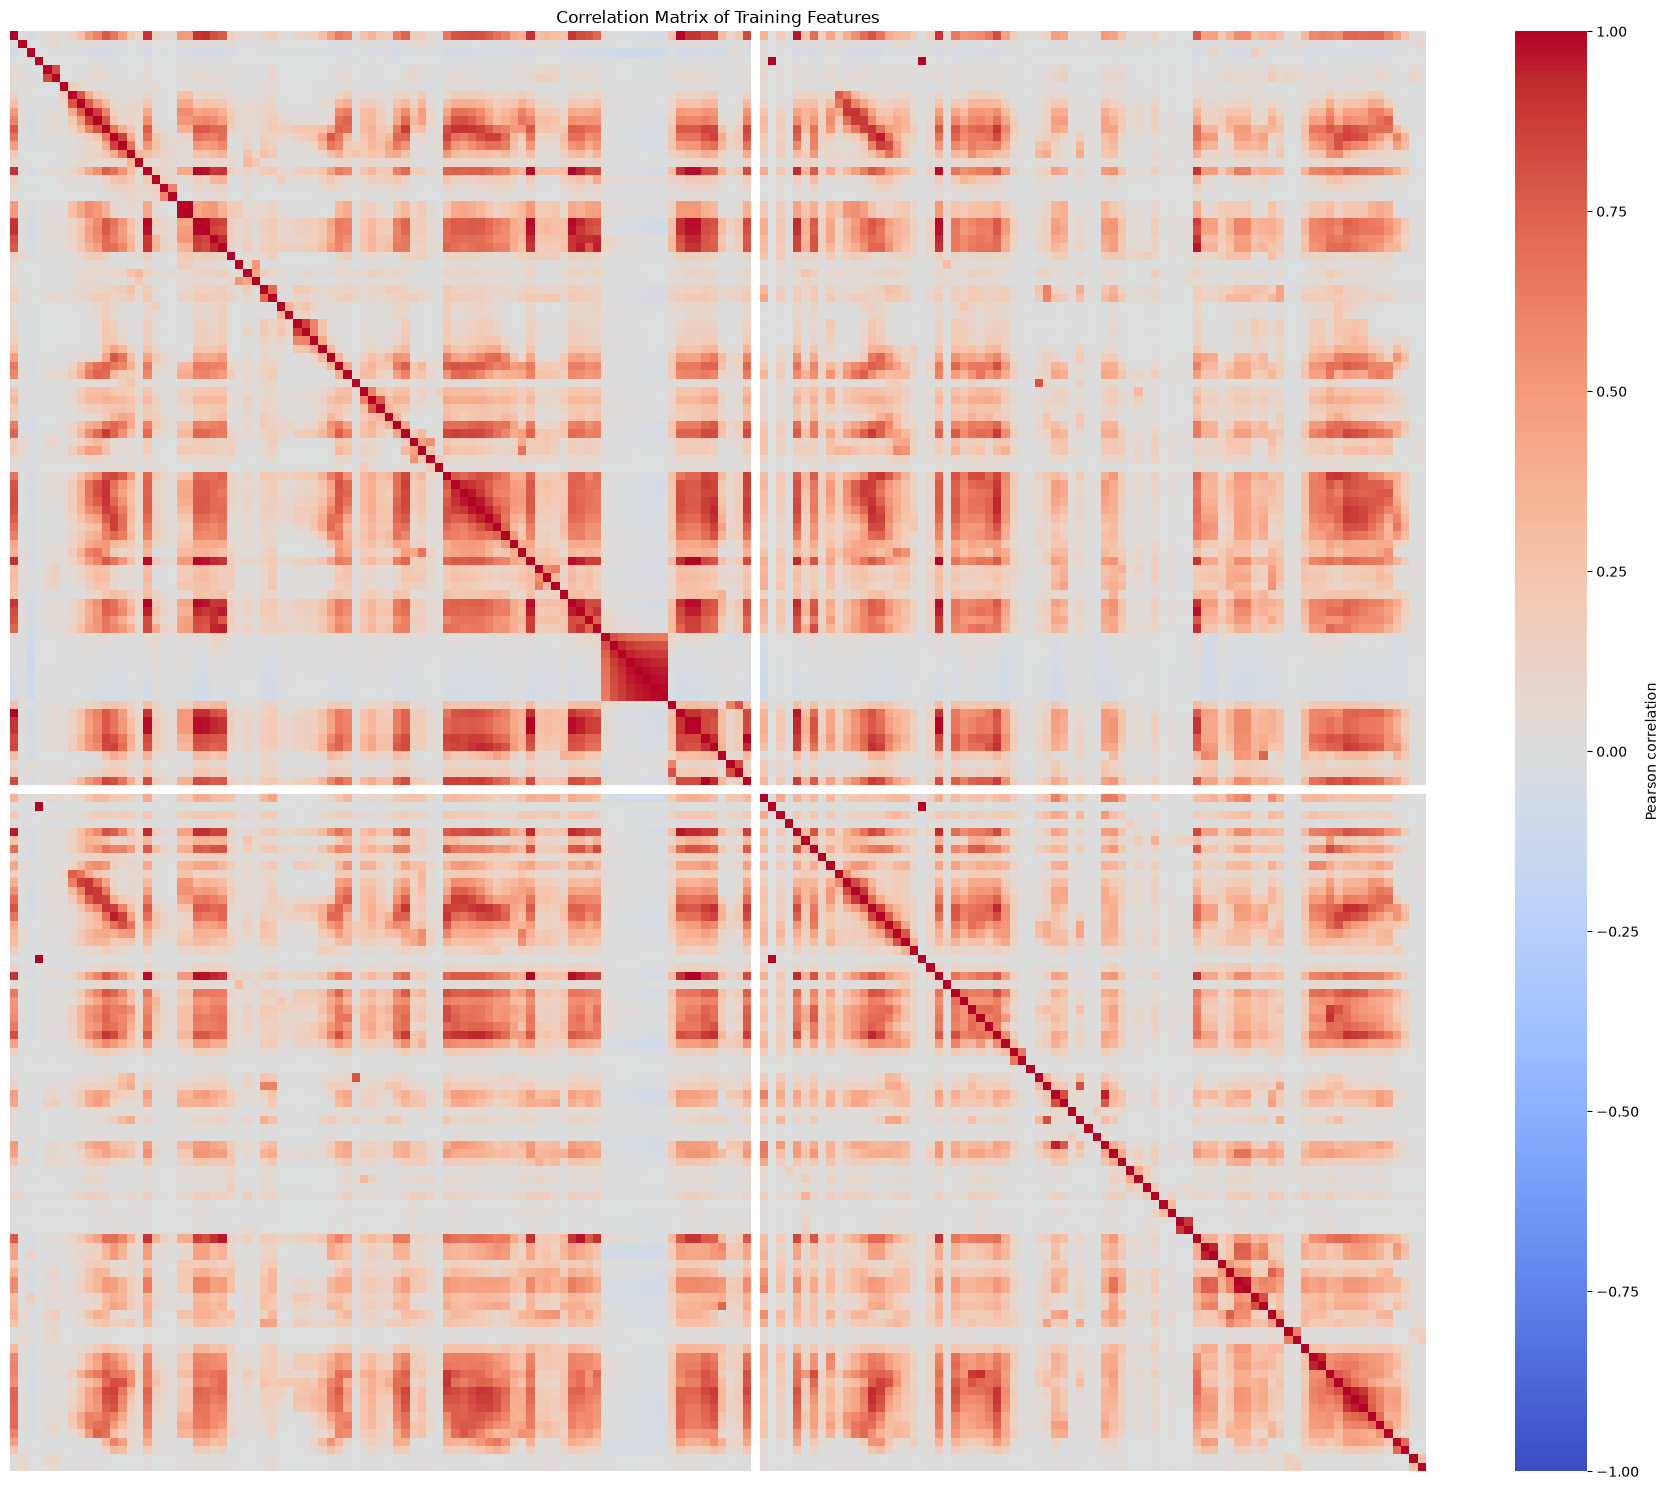

In [25]:
corr_matrix = X_train_imputed.corr(method="pearson")

plt.figure(figsize=(18, 15))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title("Correlation Matrix of Training Features")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

Number of features selected: 13
Selected features and CV values:
cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751
dtype: float64


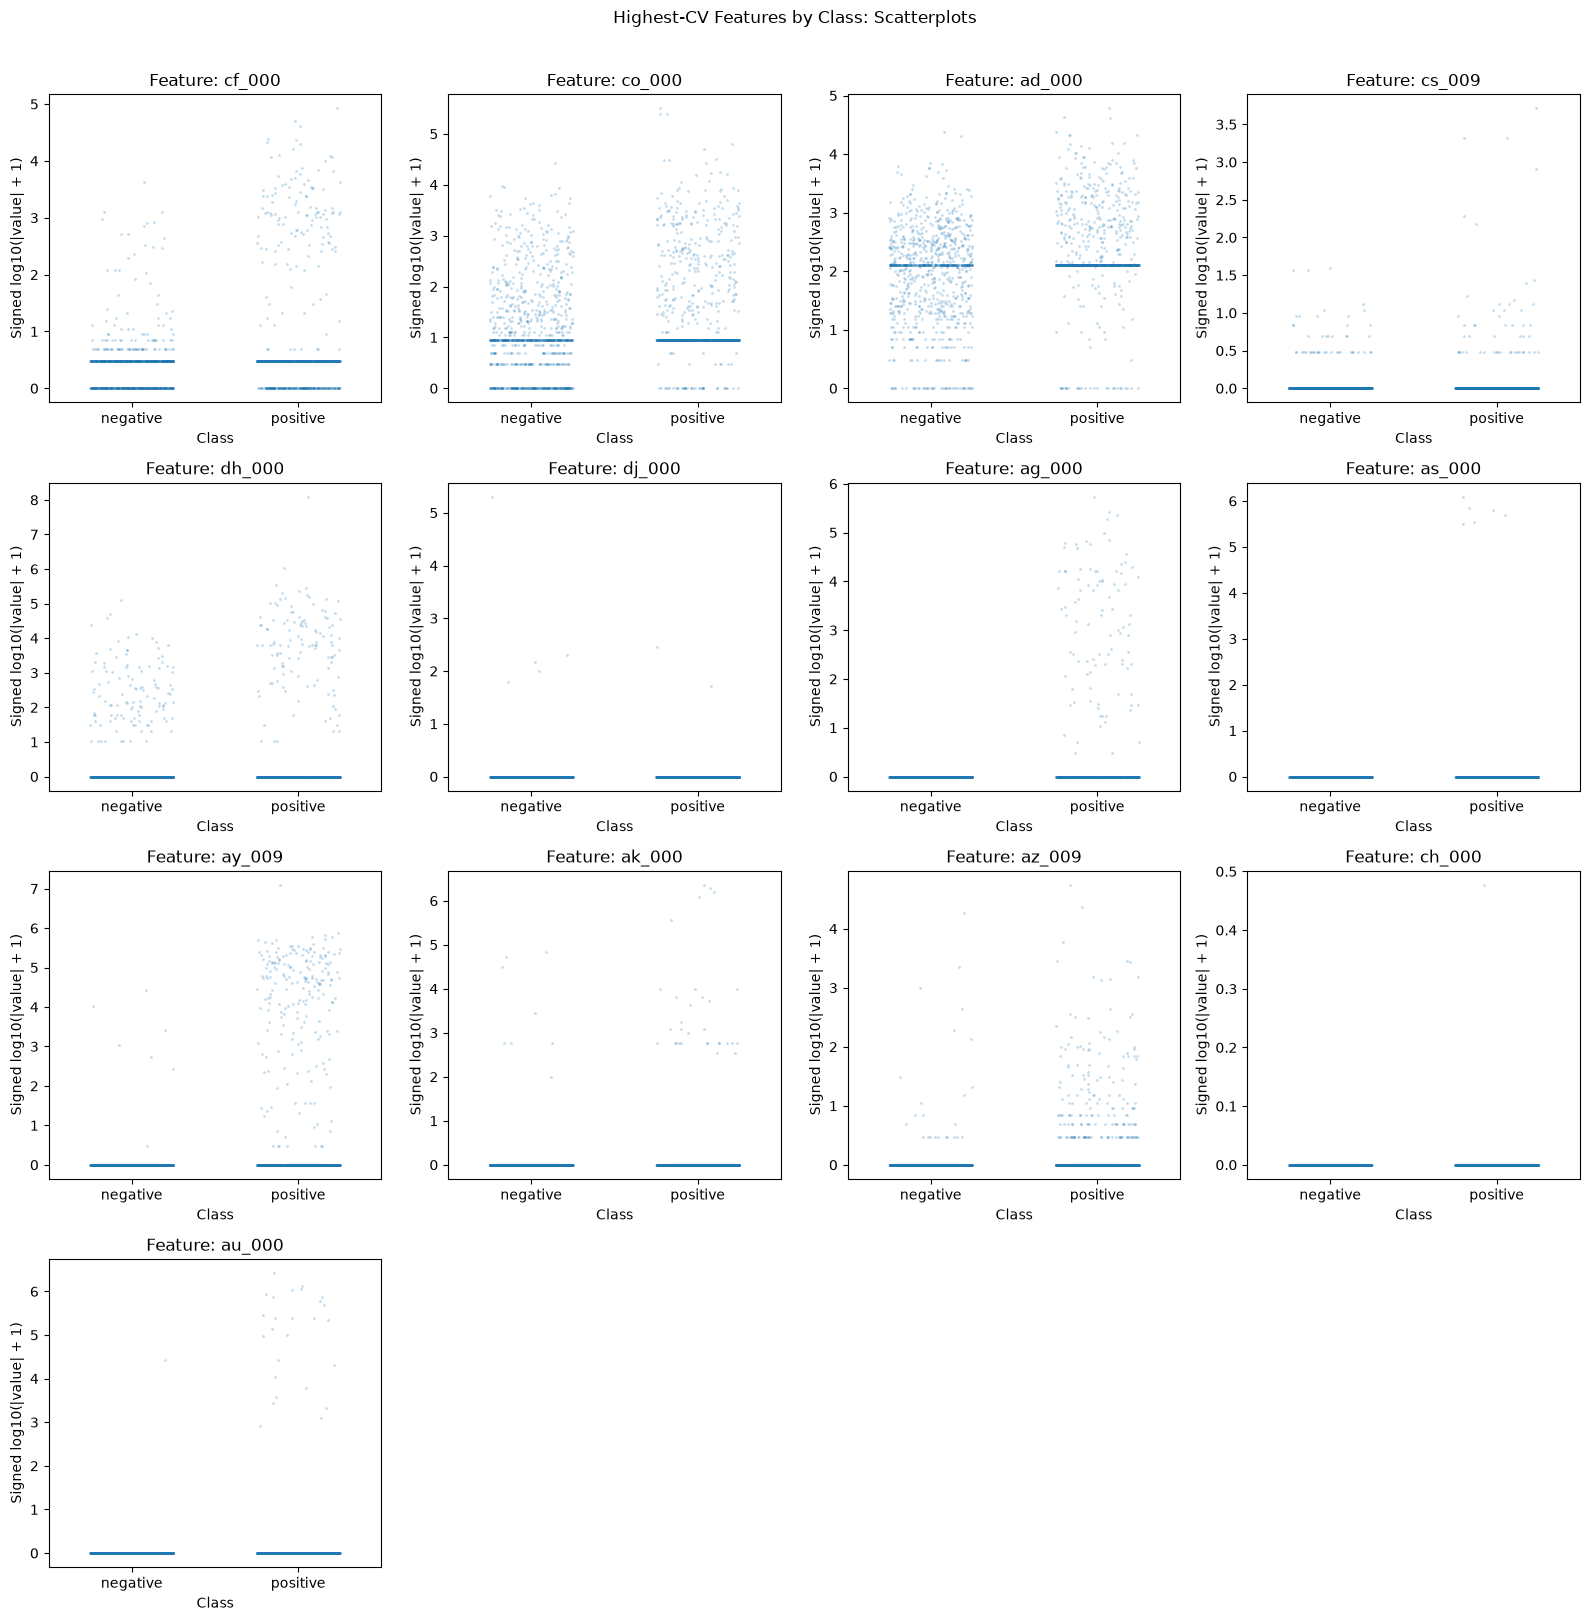

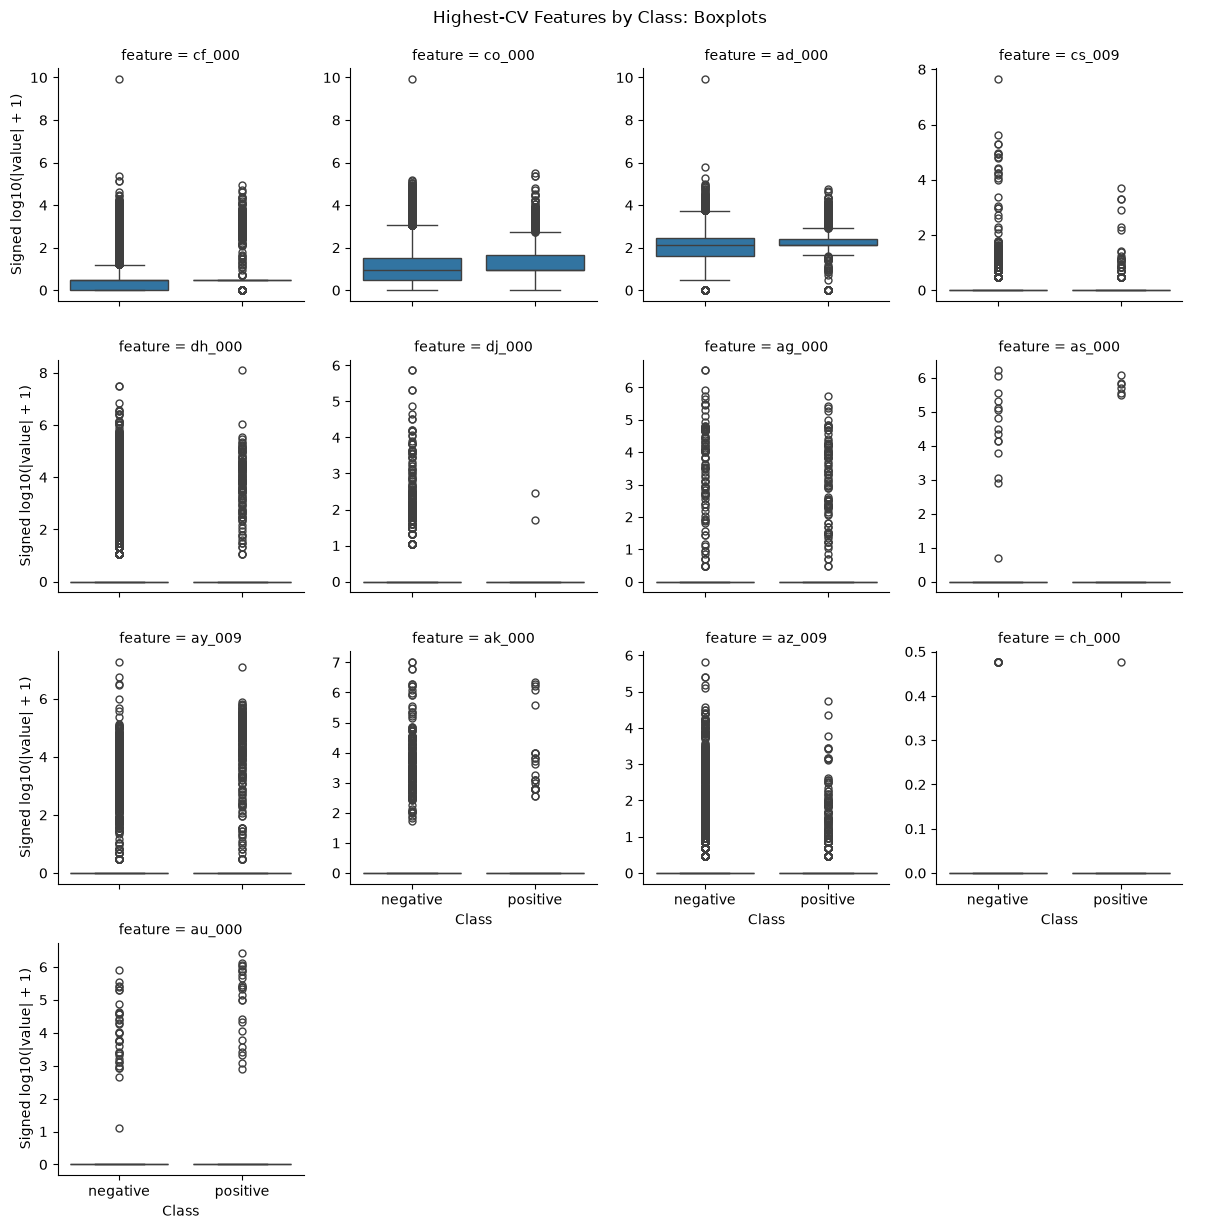

In [32]:
# Calculate CV and select floor(sqrt(170)) = 13 features
cv = X_train_imputed.std(ddof=1) / X_train_imputed.mean()
cv = cv.replace([np.inf, -np.inf], np.nan).dropna()

n_top = int(np.floor(np.sqrt(X_train_imputed.shape[1])))
top_features = cv.nlargest(n_top).index.tolist()

print(f"Number of features selected: {n_top}")
print("Selected features and CV values:")
print(cv.loc[top_features])

# Align class labels with the rows in X_train_imputed
if isinstance(y_train, pd.Series):
    y = pd.Series(y_train.to_numpy(), index=X_train_imputed.index, name="class_label")
else:
    y = pd.Series(np.asarray(y_train).ravel(), index=X_train_imputed.index, name="class_label")

# Assumes 0 = negative and 1 = positive, as in your plot
y = y.replace({
    0: "negative",
    1: "positive",
    "neg": "negative",
    "pos": "positive"
})

# Reshape the selected features for plotting
plot_df = X_train_imputed[top_features].copy()
plot_df["class_label"] = y
plot_df = plot_df.melt(
    id_vars="class_label",
    var_name="feature",
    value_name="value"
)

# Signed log transformation for visualization
plot_df["log_value"] = np.sign(plot_df["value"]) * np.log10(
    1 + np.abs(plot_df["value"])
)

# Sample up to 1,000 observations per feature per class for scatterplots
scatter_sample = pd.concat(
    [
        group.sample(n=min(len(group), 1000), random_state=42)
        for _, group in plot_df.groupby(["feature", "class_label"])
    ],
    ignore_index=True
)

# Scatterplots: feature values by class
ncols = 4
nrows = int(np.ceil(n_top / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = np.array(axes).reshape(-1)

for ax, feature in zip(axes, top_features):
    feature_data = scatter_sample[scatter_sample["feature"] == feature]

    sns.stripplot(
        data=feature_data,
        x="class_label",
        y="log_value",
        jitter=0.25,
        alpha=0.25,
        size=2,
        ax=ax
    )

    ax.set_title(f"Feature: {feature}")
    ax.set_xlabel("Class")
    ax.set_ylabel("Signed log10(|value| + 1)")

# Remove unused panels
for ax in axes[n_top:]:
    ax.remove()

fig.suptitle("Highest-CV Features by Class: Scatterplots", y=1.01)
plt.tight_layout()
plt.show()

# Boxplots: feature distributions by class
g = sns.catplot(
    data=plot_df,
    x="class_label",
    y="log_value",
    col="feature",
    col_wrap=4,
    kind="box",
    sharey=False,
    height=3
)

g.set_axis_labels("Class", "Signed log10(|value| + 1)")
g.fig.suptitle("Highest-CV Features by Class: Boxplots", y=1.02)
plt.show()

**Answer:**

*Can we conclude significance from the scatterplots?* No. The plots can suggest possible differences, but they cannot establish statistical significance or whether a feature will improve a model. The features were chosen for high CV, which measures variability relative to the mean, not class separation.

#### (v) Is this data set imbalanced?

In [35]:
# Read the original target labels, then remove any extra spaces
class_labels = train_df["class"].astype(str).str.strip().str.lower()

print("Labels found:", class_labels.unique())

class_counts = class_labels.value_counts().reindex(
    ["neg", "pos"],
    fill_value=0
)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": (class_counts / class_counts.sum() * 100).round(2)
})

display(class_summary)
print(f'Negative-to-positive ratio: {class_counts["neg"] / class_counts["pos"]:.0f}:1')

Labels found: <ArrowStringArray>
['neg', 'pos']
Length: 2, dtype: str


,Count,Percentage
class,,
neg,59000,98.33
pos,1000,1.67


Negative-to-positive ratio: 59:1


**Answer:**

The training set contains 59,000 negative cases and 1,000 positive cases. This is a highly imbalanced dataset: the negative class makes up about 98.3% of the data, while the positive class makes up about 1.7%, a ratio of 59 negative cases for every positive case.

### (c) Train a random forest

#### 1. fit the model

In [38]:
rf_model = RandomForestClassifier(
    n_estimators=500,
    random_state=17,
    oob_score=True,
    class_weight=None,
    n_jobs=-1,
    verbose=1
)
rf_model.fit(X_train_imputed, y_train)


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    3.3s
[Parallel(n_jobs=-1)]: Done 184 tasks      | elapsed:   15.2s
[Parallel(n_jobs=-1)]: Done 434 tasks      | elapsed:   35.3s
[Parallel(n_jobs=-1)]: Done 500 out of 500 | elapsed:   40.9s finished


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",17
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'


#### 2. predict porbability of the classes

In [43]:
pos_label = 1
pos_index = list(rf_model.classes_).index(pos_label)

train_pred = rf_model.predict(X_train_imputed)
test_pred = rf_model.predict(X_test_imputed)

train_prob = rf_model.predict_proba(X_train_imputed)[:, pos_index]
test_prob = rf_model.predict_proba(X_test_imputed)[:, pos_index]

train_auc = roc_auc_score(y_train == pos_label, train_prob)
test_auc = roc_auc_score(y_test == pos_label, test_prob)

[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.1s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.2s
[Parallel(n_jobs=8)]: Done 434 tasks      | elapsed:    0.5s
[Parallel(n_jobs=8)]: Done 500 out of 500 | elapsed:    0.5s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 434 tasks      | elapsed:    0.1s
[Parallel(n_jobs=8)]: Done 500 out of 500 | elapsed:    0.1s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.1s
[Parallel(n_jobs=8)]: Done 434 tasks      | elapsed:    0.4s
[Parallel(n_jobs=8)]: Done 500 out of 500 | elapsed:    0.4s finished
[

#### 3. print confusion matrices

In [ ]:
train_cm = confusion_matrix(y_train, train_pred, labels=[0, 1])
test_cm = confusion_matrix(y_test, test_pred, labels=[0, 1])

print("Rows: actual [0, 1]; columns: predicted [0, 1]")
print("Training confusion matrix:\n", train_cm)
print("Test confusion matrix:\n", test_cm)

Rows: actual [0, 1]; columns: predicted [0, 1]
Training confusion matrix:
 [[59000     0]
 [    0  1000]]
Test confusion matrix:
 [[15608    17]
 [  104   271]]


#### 4. calculate OC, AUC, and misclassification for training and test sets


Training misclassification rate: 0.0000
Test misclassification rate:     0.0076
Training AUC: 1.0000
Test AUC:     0.9940
OOB error estimate: 0.0059
Test error:          0.0076


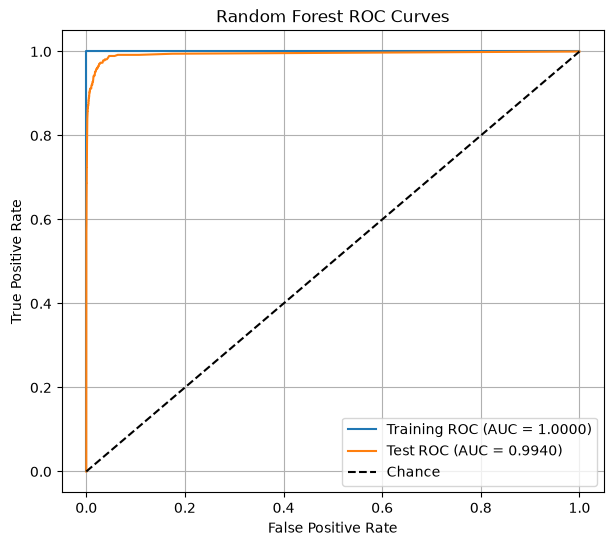

In [48]:
y_train_array = np.asarray(y_train).ravel()
y_test_array = np.asarray(y_test).ravel()

# Misclassification rates
train_error = np.mean(train_pred != y_train)
test_error = np.mean(test_pred != y_test)

print(f"\nTraining misclassification rate: {train_error:.4f}")
print(f"Test misclassification rate:     {test_error:.4f}")

# ROC and AUC
train_auc = roc_auc_score(y_train_array, train_prob)
test_auc = roc_auc_score(y_test_array, test_prob)

train_fpr, train_tpr, _ = roc_curve(y_train_array == 1, train_prob)
test_fpr, test_tpr, _ = roc_curve(y_test_array == 1, test_prob)

print(f"Training AUC: {train_auc:.4f}")
print(f"Test AUC:     {test_auc:.4f}")

# Out-of-bag error estimate
oob_error = 1 - rf_model.oob_score_
print(f"OOB error estimate: {oob_error:.4f}")
print(f"Test error:          {test_error:.4f}")

plt.figure(figsize=(7, 6))
plt.plot(train_fpr, train_tpr, label=f"Training ROC (AUC = {train_auc:.4f})")
plt.plot(test_fpr, test_tpr, label=f"Test ROC (AUC = {test_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

**Answer:**

The training misclassification rate was 0.0000, with an AUC of 1.0000. The perfect training results are less informative because they were calculated on the data used to fit the forest. On the test set, the misclassification rate was 0.0076 (0.76%), and the AUC was 0.9940. The OOB error estimate was 0.0059 (0.59%), which is close to the test error of 0.76%. This suggests the OOB estimate was a reasonable approximation of the test error.

### (d) Research class imbalance in random forest

#### 1. Keep the 1c settings and change only the class weighting

In [73]:
balanced_rf = clone(rf_model).set_params(
    class_weight="balanced_subsample"
)

balanced_rf.fit(X_train_imputed, y_train)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    1.9s
[Parallel(n_jobs=-1)]: Done 184 tasks      | elapsed:    9.9s
[Parallel(n_jobs=-1)]: Done 434 tasks      | elapsed:   22.8s
[Parallel(n_jobs=-1)]: Done 500 out of 500 | elapsed:   25.9s finished


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",17
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",1
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the

#### 2. Find the probability column for the positive class

In [74]:
positive_label = 1
positive_col = list(balanced_rf.classes_).index(positive_label)

train_pred = balanced_rf.predict(X_train_imputed)
test_pred = balanced_rf.predict(X_test_imputed)

train_prob = balanced_rf.predict_proba(X_train_imputed)[:, positive_col]
test_prob = balanced_rf.predict_proba(X_test_imputed)[:, positive_col]

[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.1s
[Parallel(n_jobs=8)]: Done 434 tasks      | elapsed:    0.3s
[Parallel(n_jobs=8)]: Done 500 out of 500 | elapsed:    0.4s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 434 tasks      | elapsed:    0.1s
[Parallel(n_jobs=8)]: Done 500 out of 500 | elapsed:    0.1s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.1s
[Parallel(n_jobs=8)]: Done 434 tasks      | elapsed:    0.3s
[Parallel(n_jobs=8)]: Done 500 out of 500 | elapsed:    0.4s finished
[

#### 3. Present Results

In [75]:
print(f"Training misclassification rate: {1 - accuracy_score(y_train, train_pred):.4f}")
print(f"Test misclassification rate:     {1 - accuracy_score(y_test, test_pred):.4f}")
print(f"Training AUC: {roc_auc_score(y_train, train_prob):.4f}")
print(f"Test AUC:     {roc_auc_score(y_test, test_prob):.4f}")
print(f"Training balanced accuracy: {balanced_accuracy_score(y_train, train_pred):.4f}")
print(f"Test balanced accuracy:     {balanced_accuracy_score(y_test, test_pred):.4f}")
print(f"Test positive-class precision: {precision_score(y_test, test_pred, pos_label=positive_label):.4f}")
print(f"Test positive-class recall:    {recall_score(y_test, test_pred, pos_label=positive_label):.4f}")
print(f"Test average precision:        {average_precision_score(y_test, test_prob, pos_label=positive_label):.4f}")

print("Test confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, test_pred, labels=[0, 1]))

print(f"OOB error estimate: {1 - balanced_rf.oob_score_:.4f}")

Training misclassification rate: 0.0000
Test misclassification rate:     0.0108
Training AUC: 1.0000
Test AUC:     0.9945
Training balanced accuracy: 1.0000
Test balanced accuracy:     0.7902
Test positive-class precision: 0.9356
Test positive-class recall:    0.5813
Test average precision:        0.8850
Test confusion matrix (rows = actual, columns = predicted):
[[15610    15]
 [  157   218]]
OOB error estimate: 0.0072


**Answer:**

I addressed class imbalance by setting class_weight="balanced_subsample", which adjusts class weights for each tree’s bootstrap sample. Compared with the original model, the weighted model had a slightly higher test misclassification rate (0.0108 vs. 0.0076), a slightly higher test AUC (0.9945 vs. 0.9940), and a higher OOB error estimate (0.0072 vs. 0.0059). Across these three metrics, the weighted model performed slightly worse than the original model.

### (e) XGBoost and Model Trees

#### 1. Set Up Model + Cross validate

In [67]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=17
)

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=17,
    n_jobs=-1
)

param_grid = {
    "reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]
}

grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    refit=True,
    n_jobs=1,
    verbose=1
)

#### 2. fit model and report performance

In [76]:
grid_search.fit(X_train_imputed, y_train)

best_model = grid_search.best_estimator_

cv_error = 1 - grid_search.best_score_

print(f"Best alpha (reg_alpha): {grid_search.best_params_['reg_alpha']}")
print(f"5-fold CV misclassification rate: {cv_error:.4f}")

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best alpha (reg_alpha): 0.1
5-fold CV misclassification rate: 0.0064


#### 3. Calculate Training and Test Set predicitons and errors

In [77]:
class_names = [0, 1]

y_train_pred = best_model.predict(X_train_imputed)
y_test_pred = best_model.predict(X_test_imputed)

y_train_prob = best_model.predict_proba(X_train_imputed)[:, 1]
y_test_prob = best_model.predict_proba(X_test_imputed)[:, 1]

train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)

print(f"Training misclassification rate: {train_error:.4f}")
print(f"Test misclassification rate:     {test_error:.4f}")

Training misclassification rate: 0.0026
Test misclassification rate:     0.0079


#### 4. Display Training and Test Confusion matrices

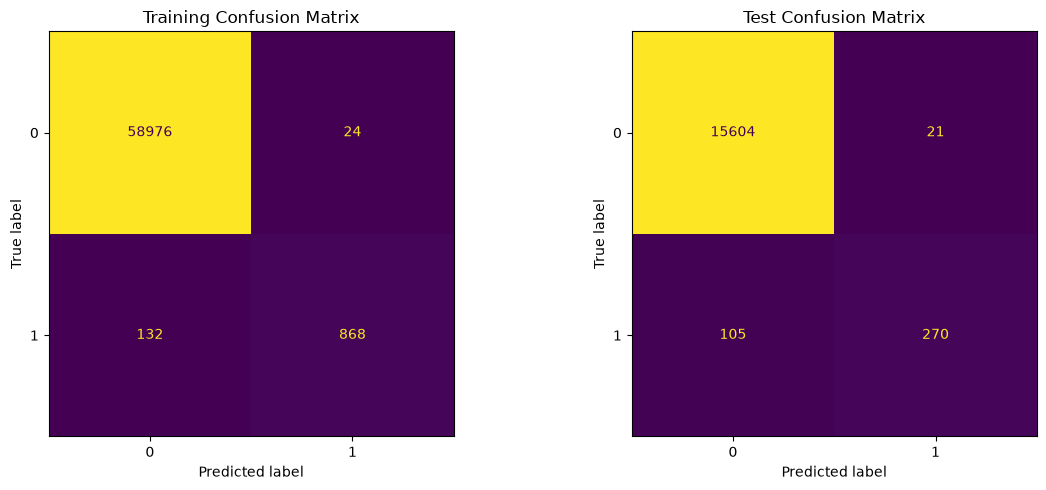

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix(y_train, y_train_pred, labels=[0, 1]),
    display_labels=class_names
).plot(ax=axes[0], values_format="d", colorbar=False)
axes[0].set_title("Training Confusion Matrix")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_test_pred, labels=[0, 1]),
    display_labels=class_names
).plot(ax=axes[1], values_format="d", colorbar=False)
axes[1].set_title("Test Confusion Matrix")

plt.tight_layout()
plt.show()

#### 5. calculate AUC and ROC curves

Training AUC: 0.9986
Test AUC:     0.9965


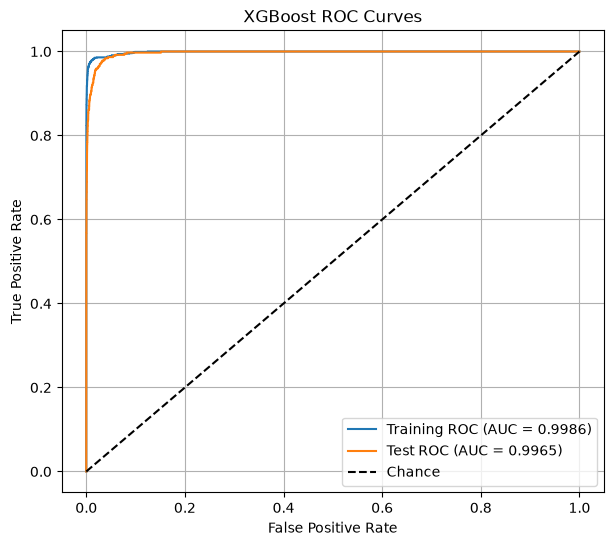

In [79]:
train_auc = roc_auc_score(y_train, y_train_prob)
test_auc = roc_auc_score(y_test, y_test_prob)

train_fpr, train_tpr, _ = roc_curve(y_train, y_train_prob)
test_fpr, test_tpr, _ = roc_curve(y_test, y_test_prob)

print(f"Training AUC: {train_auc:.4f}")
print(f"Test AUC:     {test_auc:.4f}")

plt.figure(figsize=(7, 6))
plt.plot(train_fpr, train_tpr, label=f"Training ROC (AUC = {train_auc:.4f})")
plt.plot(test_fpr, test_tpr, label=f"Test ROC (AUC = {test_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

**Answer:**

I fit an XGBoost classifier without class-imbalance compensation and used 5-fold cross-validation to select reg_alpha; the best value was 0. The cross-validation misclassification rate was 0.0064, compared with 0.0079 on the test set, and the AUC was 0.9986 for training and 0.9965 for testing. On the test set, the model correctly identified 270 of 375 positive cases and missed 105, while producing 21 false positives. The similar test and cross-validation errors and high test AUC indicate strong overall performance, though some positive cases were still missed.

### (f) Use SMOTE to pre-process your data

#### 1. set up CV and XG Boost classifer

In [86]:
cv_splitter = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=17
)

print(type(cv_splitter))
print("Has split method:", hasattr(cv_splitter, "split"))
print("Number of folds:", len(list(cv_splitter.split(X_train_imputed, y_train))))

smote_pipeline = ImbPipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("xgb", xgb_model)
])

smote_param_grid = {
    "xgb__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]
}

smote_search = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=smote_param_grid,
    scoring="accuracy",
    cv=cv_splitter,
    refit=True,
    n_jobs=1,
    verbose=1
)

smote_search.fit(X_train_imputed, y_train)

<class 'sklearn.model_selection._split.StratifiedKFold'>
Has split method: True
Number of folds: 5
Fitting 5 folds for each of 6 candidates, totalling 30 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'xgb__reg_alpha': [0, 0.001, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see

#### 2. Tune Uncompensated Model

In [ ]:
uncompensated_pipeline = ImbPipeline([
    ("scale", StandardScaler()),
    ("xgb", xgb)
])

uncompensated_search = GridSearchCV(
    estimator=uncompensated_pipeline,
    param_grid=alpha_grid,
    scoring="accuracy", 
    cv=cv_splitter,
    n_jobs=1,
    refit=True
)

uncompensated_search.fit(X_train_imputed, y_train)

print("Best alpha:", uncompensated_search.best_params_)
print("Best CV ROC AUC:", uncompensated_search.best_score_)

KeyboardInterrupt: 

## 2. ISLR 6.6.3

## 3. ISLR 6.6.5

## 4. ISLR 8.4.5

## 5. ISLR 9.7.3